# Task 1: Sales & Demand Forecasting for Businesses
**Future Interns · Machine Learning Track · `FUTURE_ML_01`**

## Business problem
A retail business needs to know **how much it will sell in the coming months** so it can plan inventory, cash flow and staffing, and avoid overstocking or running out of stock.

## What this notebook does
| Step | What | Why it matters to the business |
|---|---|---|
| 1 | Load & clean the data | Bad data gives bad forecasts |
| 2 | Aggregate to monthly sales | Stable, easy-to-explain level for planning |
| 3 | Explore trend & seasonality | Explains *why* sales move |
| 4 | Time-based feature engineering | Gives regression models a sense of time |
| 5 | Train & compare 6 models against a baseline | A model is only useful if it beats a simple rule |
| 6 | Evaluate errors (MAE, RMSE, MAPE) + backtest | Tells the business how far it can trust the forecast |
| 7 | Forecast the next 12 months | The actual deliverable |
| 8 | Business insights & recommendations | Turns numbers into decisions |

**Dataset:** Superstore Sales (Kaggle: `vivek468/superstore-dataset-final`), about 10K orders from Jan 2014 to Dec 2017.

## 1. Setup

In [1]:
# Colab already has all of these. If running locally, uncomment the next line:
# !pip install pandas numpy matplotlib seaborn scikit-learn statsmodels

import os, glob, zipfile, calendar, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 100})

for folder in ["data", "images", "outputs"]:
    os.makedirs(folder, exist_ok=True)

RANDOM_STATE = 42
BLUE, ORANGE, GREEN, RED, GREY = "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#7f7f7f"
print("Setup complete")

Setup complete


## 2. Load the data
This cell finds the Superstore CSV automatically. It works whether you uploaded the **zip** or the **CSV** to Colab. If it can't find either, it opens an upload dialog.

In [2]:
def find_csv():
    patterns = ["data/**/*uperstore*.csv", "*uperstore*.csv", "/content/**/*uperstore*.csv"]
    for p in patterns:
        hits = glob.glob(p, recursive=True)
        if hits:
            return hits[0]
    return None

csv_path = find_csv()

# 1) not found? try extracting any zip file sitting next to the notebook
if csv_path is None:
    for z in glob.glob("*.zip") + glob.glob("/content/*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall("data")
    csv_path = find_csv()

# 2) still not found? ask for an upload (Colab only)
if csv_path is None:
    try:
        from google.colab import files
        print("Upload the Superstore zip or CSV file:")
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name) as zf:
                    zf.extractall("data")
            else:
                os.replace(name, os.path.join("data", name))
        csv_path = find_csv()
    except ImportError:
        pass

if csv_path is None:
    raise FileNotFoundError("Superstore CSV not found. Upload the zip or CSV next to this notebook.")

print("Using file:", csv_path)
df = pd.read_csv(csv_path, encoding="latin-1")   # latin-1 avoids a common Superstore encoding error

# Dates in this file are US format: month/day/year. Being explicit prevents silent month/day mix-ups.
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df.head()

Using file: Sample - Superstore.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. Inspect and clean the data

In [3]:
print("Shape            :", df.shape)
print("Date range       :", df["Order Date"].min().date(), "->", df["Order Date"].max().date())
print("Duplicate rows   :", df.duplicated().sum())
print("Missing values   :", int(df.isna().sum().sum()))
print("Non-positive sales:", int((df["Sales"] <= 0).sum()))
print()
df[["Sales", "Quantity", "Discount", "Profit"]].describe().round(2)

Shape            : (9994, 21)
Date range       : 2014-01-03 -> 2017-12-30
Duplicate rows   : 0
Missing values   : 0
Non-positive sales: 0



,Sales,Quantity,Discount,Profit
count,9994.00,9994.00,9994.00,9994.00
mean,229.86,3.79,0.16,28.66
std,623.25,2.23,0.21,234.26
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.49,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


In [4]:
# Cleaning steps (each one is logged so it is easy to explain)
rows_before = len(df)

df = df.drop_duplicates()                              # 1. remove exact duplicate rows
df = df.dropna(subset=["Order Date", "Sales"])         # 2. a sale without a date or amount can't be used
df = df[df["Sales"] > 0]                               # 3. sales must be positive

print(f"Rows before: {rows_before:,} | after: {len(df):,} | removed: {rows_before - len(df):,}")

# Outlier check: we LOOK at the biggest orders but keep them.
# They are real large purchases, not errors, and removing them would hide genuine demand.
df.nlargest(5, "Sales")[["Order Date", "Category", "Sub-Category", "Sales"]]

Rows before: 9,994 | after: 9,994 | removed: 0


,Order Date,Category,Sub-Category,Sales
2697,2014-03-18,Technology,Machines,22638.480
6826,2016-10-02,Technology,Copiers,17499.950
8153,2017-03-23,Technology,Copiers,13999.960
2623,2017-10-22,Technology,Copiers,11199.968
4190,2017-11-17,Technology,Copiers,10499.970


**Cleaning notes (write-up):**
- **Duplicates / missing values / non-positive sales:** all three checks are run and any problem rows are removed. The counts above show exactly what was removed.
- **Date format:** parsed explicitly as month/day/year, because guessing the format can silently swap days and months.
- **Outliers:** the largest orders were inspected and **kept**. They are genuine big purchases, so deleting them would understate real demand.

## 4. Turn orders into a monthly time series
Individual orders are too noisy for planning, so we sum sales per month. Monthly is also the level where businesses order stock and manage cash.

48 months: Jan 2014 -> Dec 2017


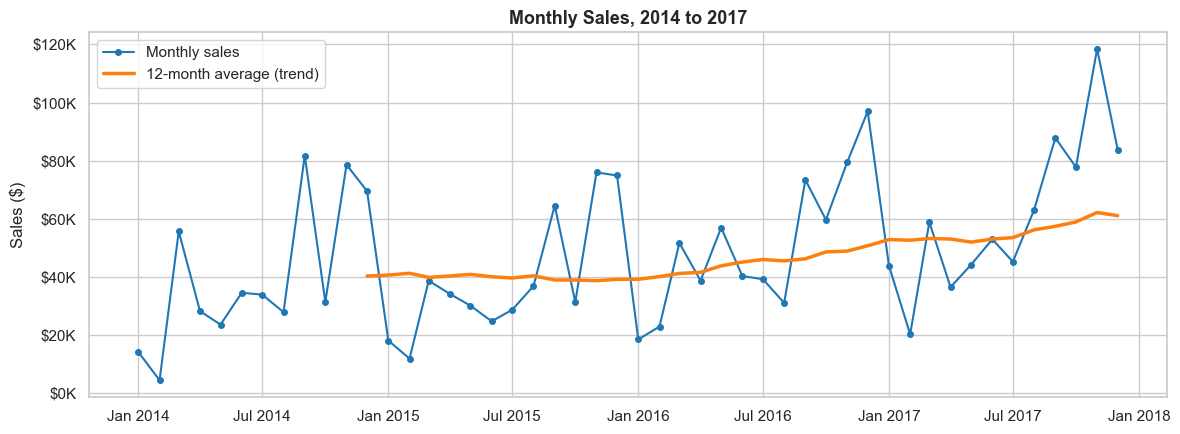

In [5]:
series = df.set_index("Order Date")["Sales"].resample("MS").sum()      # MS = month start

# Make sure no month is missing (a missing month would break lag features)
full_range = pd.date_range(series.index.min(), series.index.max(), freq="MS")
series = series.reindex(full_range, fill_value=0.0)
series.index.name = "Month"
series.name = "sales"

print(f"{len(series)} months: {series.index[0]:%b %Y} -> {series.index[-1]:%b %Y}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(series.index, series.values, marker="o", ms=4, color=BLUE, label="Monthly sales")
ax.plot(series.index, series.rolling(12).mean(), color=ORANGE, lw=2.5, label="12-month average (trend)")
ax.set_title("Monthly Sales, 2014 to 2017")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
ax.legend()
plt.tight_layout()
plt.savefig("images/01_monthly_sales.png", dpi=150)
plt.show()

## 5. Explore trend and seasonality
Three questions: **Is the business growing? Is there a yearly pattern? Which months matter most?**

### 5.1 Decomposition
A time series is split into **trend** (long-term direction), **seasonality** (repeating yearly pattern) and **residual** (random noise).

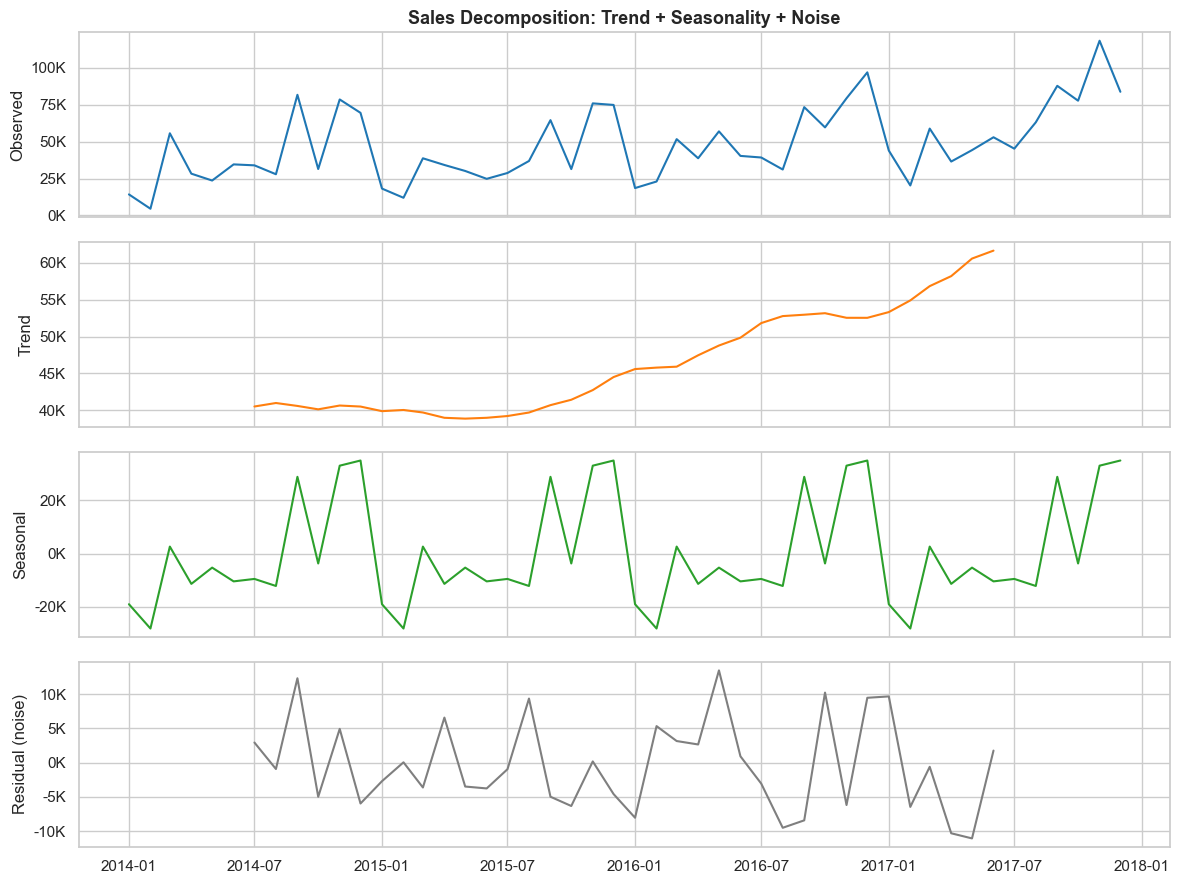

In [6]:
decomp = seasonal_decompose(series, model="additive", period=12)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, (title, data, color) in zip(
    axes,
    [("Observed", decomp.observed, BLUE), ("Trend", decomp.trend, ORANGE),
     ("Seasonal", decomp.seasonal, GREEN), ("Residual (noise)", decomp.resid, GREY)]):
    ax.plot(data, color=color)
    ax.set_ylabel(title)
    ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:,.0f}K")
axes[0].set_title("Sales Decomposition: Trend + Seasonality + Noise")
plt.tight_layout()
plt.savefig("images/02_decomposition.png", dpi=150)
plt.show()

### 5.2 Which months are strong or weak, and how fast is the business growing?

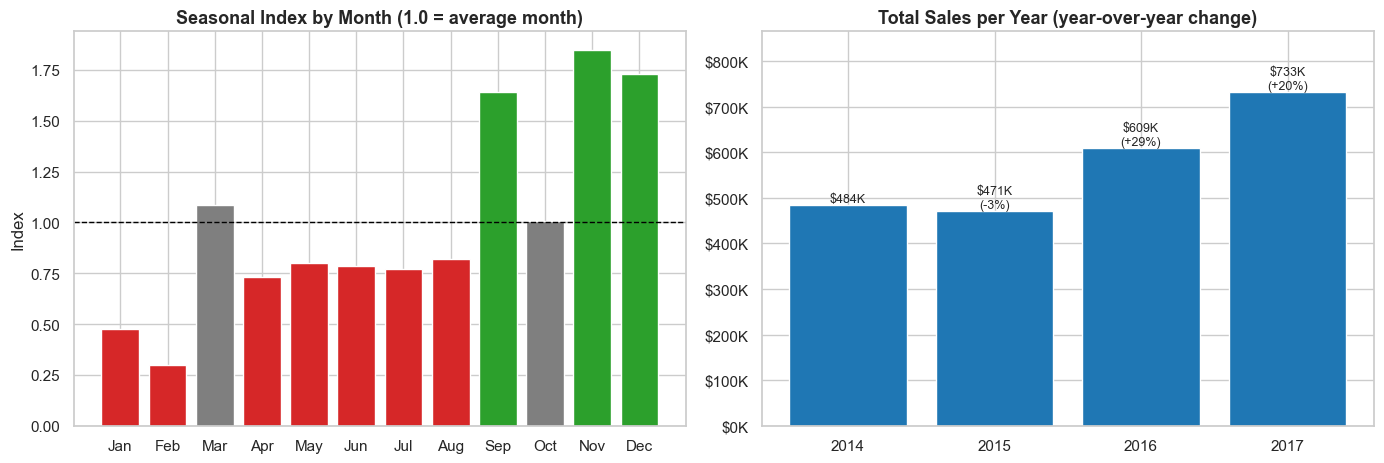

Yearly totals ($):
Month
2014    484247.0
2015    470533.0
2016    609206.0
2017    733215.0

Compound annual growth 2014->2017: 14.8% per year


In [7]:
# Seasonal index = a month's sales / that year's average month. 1.0 = average, 1.5 = 50% above average.
# Dividing by the yearly average removes growth, so we compare months fairly across years.
yearly_avg = series.groupby(series.index.year).transform("mean")
seasonal_index = (series / yearly_avg).groupby(series.index.month).mean()

yearly_total = series.groupby(series.index.year).sum()
yoy_growth = yearly_total.pct_change() * 100
cagr = ((yearly_total.iloc[-1] / yearly_total.iloc[0]) ** (1 / (len(yearly_total) - 1)) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# (a) seasonality
colors = [GREEN if v >= 1.15 else RED if v <= 0.85 else GREY for v in seasonal_index.values]
axes[0].bar([calendar.month_abbr[m] for m in seasonal_index.index], seasonal_index.values, color=colors)
axes[0].axhline(1, color="black", ls="--", lw=1)
axes[0].set_title("Seasonal Index by Month (1.0 = average month)")
axes[0].set_ylabel("Index")

# (b) yearly totals with growth labels
bars = axes[1].bar(yearly_total.index.astype(str), yearly_total.values, color=BLUE)
for bar, g in zip(bars, yoy_growth.values):
    label = f"${bar.get_height()/1000:,.0f}K" + ("" if np.isnan(g) else f"\n({g:+.0f}%)")
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height(), label, ha="center", va="bottom", fontsize=9)
axes[1].set_title("Total Sales per Year (year-over-year change)")
axes[1].yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
axes[1].set_ylim(0, yearly_total.max() * 1.18)

plt.tight_layout()
plt.savefig("images/03_seasonality_and_growth.png", dpi=150)
plt.show()

print("Yearly totals ($):")
print(yearly_total.round(0).to_string())
print(f"\nCompound annual growth 2014->{yearly_total.index[-1]}: {cagr:.1f}% per year")

### 5.3 Where does the money come from? (business context)

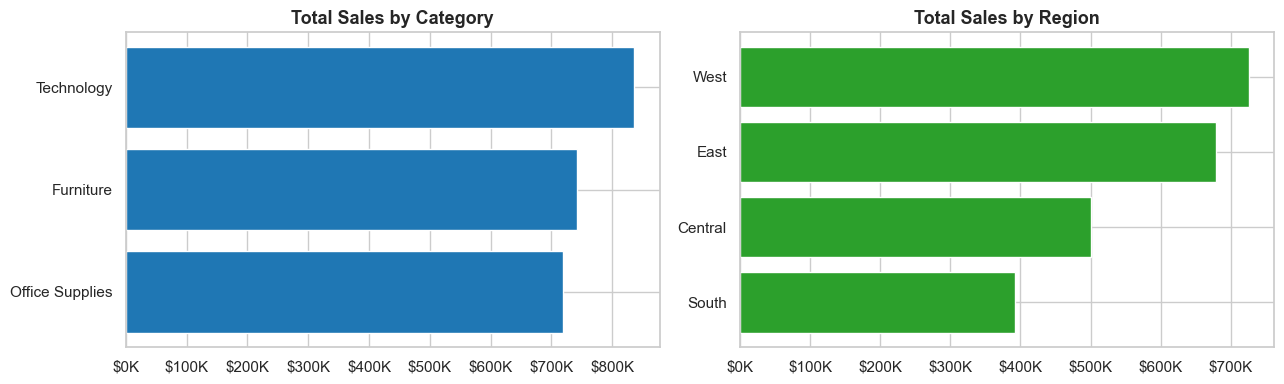

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, color in zip(axes, ["Category", "Region"], [BLUE, GREEN]):
    totals = df.groupby(col)["Sales"].sum().sort_values()
    ax.barh(totals.index, totals.values, color=color)
    ax.set_title(f"Total Sales by {col}")
    ax.xaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
plt.tight_layout()
plt.savefig("images/04_sales_by_category_region.png", dpi=150)
plt.show()

**What to say about these charts (write-up):**
1. **Trend:** sales dipped slightly in 2015, then grew strongly in 2016 and 2017, so planning must assume growth, not a flat business.
2. **Seasonality:** the same months are strong every year (green bars) and the same months are weak (red bars). This repeating pattern is what the forecasting models exploit.
3. **Noise:** the residual panel shows sales are lumpy, because a few big orders can swing a month. This is why forecast errors will not be tiny.

## 6. Time-based feature engineering
Regression models don't understand dates, so we turn each month into numbers:

| Feature | Meaning |
|---|---|
| `t` | Months since the start. Captures the **trend** |
| `month` | Calendar month (1 to 12) |
| `month_sin`, `month_cos` | Month encoded as a circle, so December and January are "neighbours" |
| `lag_12` | Sales in the **same month last year**. Captures yearly seasonality |

> **Why no `lag_1` (last month's sales)?** The goal is to forecast the *next 12 months*. When you forecast September 2018 you won't yet know August 2018, so a `lag_1` feature would leak information that doesn't exist at forecast time and make test scores look better than reality. `lag_12` is always known for a 12-month horizon, so every score below is honest.

In [9]:
def next_months(last_date, h):
    return pd.date_range(last_date + pd.DateOffset(months=1), periods=h, freq="MS")

def make_features(idx, hist):
    """Build time-based features for the months in `idx`, using only history from `hist`."""
    X = pd.DataFrame(index=idx)
    X["t"] = (idx.year - hist.index[0].year) * 12 + (idx.month - hist.index[0].month)
    X["month"] = idx.month
    X["month_sin"] = np.sin(2 * np.pi * idx.month / 12)
    X["month_cos"] = np.cos(2 * np.pi * idx.month / 12)
    X["lag_12"] = hist.reindex(idx - pd.DateOffset(months=12)).values   # NaN where last year is unknown
    return X

make_features(series.index, series).dropna().head(8).round(2)

,t,month,month_sin,month_cos,lag_12
Month,,,,,
2015-01-01,12,1,0.50,0.87,14236.90
2015-02-01,13,2,0.87,0.50,4519.89
2015-03-01,14,3,1.00,0.00,55691.01
2015-04-01,15,4,0.87,-0.50,28295.34
2015-05-01,16,5,0.50,-0.87,23648.29
2015-06-01,17,6,0.00,-1.00,34595.13
2015-07-01,18,7,-0.50,-0.87,33946.39
2015-08-01,19,8,-0.87,-0.50,27909.47


## 7. Build the models
Six models are compared. Every model must **beat the baseline**, a simple rule that needs no machine learning:

| Model | Type | Idea |
|---|---|---|
| **Seasonal Naive** (baseline) | Rule | "Next September = last September" |
| Linear Regression | Regression | Straight-line trend + seasonal pattern |
| Random Forest | Regression | Many decision trees, captures non-linear patterns |
| Holt-Winters | Time-series | Smooths level, trend and seasonality |
| Holt-Winters (damped) | Time-series | Same, but the trend flattens over time instead of growing forever |
| SARIMA | Time-series | Classic statistical model using past values and past errors |

Each model is wrapped in a function `model(train_series, horizon) -> forecast`, so every model is trained and tested in exactly the same way.

In [10]:
# ---------- baseline ----------
def forecast_seasonal_naive(train, h):
    idx = next_months(train.index[-1], h)
    return pd.Series(train.reindex(idx - pd.DateOffset(months=12)).values, index=idx)

# ---------- regression models ----------
def _fit_predict_regression(model, cols, train, h):
    assert h <= 12, "Regression models use lag_12, so they can forecast at most 12 months ahead."
    idx = next_months(train.index[-1], h)
    X_train = make_features(train.index, train).dropna()      # first 12 months have no lag_12
    y_train = train.loc[X_train.index]
    model.fit(X_train[cols], y_train)
    return pd.Series(model.predict(make_features(idx, train)[cols]), index=idx)

def forecast_linear(train, h):
    return _fit_predict_regression(LinearRegression(), ["t", "month_sin", "month_cos", "lag_12"], train, h)

def forecast_rf(train, h):
    rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)
    return _fit_predict_regression(rf, ["t", "month", "lag_12"], train, h)

# ---------- time-series models ----------
def forecast_holt_winters(train, h):
    m = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
    return m.forecast(h)

def forecast_holt_winters_damped(train, h):
    m = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12).fit()
    return m.forecast(h)

def forecast_sarima(train, h):
    # Only 36-48 monthly points are available, so a small, simple SARIMA is used.
    m = SARIMAX(train, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12),
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return m.forecast(h)

BASELINE = "Seasonal Naive (baseline)"
MODELS = {
    BASELINE:                forecast_seasonal_naive,
    "Linear Regression":     forecast_linear,
    "Random Forest":         forecast_rf,
    "Holt-Winters":          forecast_holt_winters,
    "Holt-Winters (damped)": forecast_holt_winters_damped,
    "SARIMA":                forecast_sarima,
}

def run_model(name, train, h):
    """Run one model and return a clean forecast Series (sales can't be negative)."""
    raw = MODELS[name](train, h)
    return pd.Series(np.clip(np.asarray(raw, dtype=float), 0, None), index=next_months(train.index[-1], h))

def metrics(y_true, y_pred):
    err = y_true.values - y_pred.values
    return {"MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE %": np.mean(np.abs(err / y_true.values)) * 100}
print("Models ready:", list(MODELS))

Models ready: ['Seasonal Naive (baseline)', 'Linear Regression', 'Random Forest', 'Holt-Winters', 'Holt-Winters (damped)', 'SARIMA']


## 8. Evaluate the models
### 8.1 Chronological train/test split
**Time-series data must never be shuffled.** We train on the past and test on the most recent 12 months, a full yearly cycle, exactly like real forecasting.

| Metric | Plain-English meaning |
|---|---|
| **MAE** | On average, the forecast is off by this many dollars per month |
| **RMSE** | Like MAE but punishes big misses more |
| **MAPE** | On average, the forecast is off by this percentage |

In [11]:
HORIZON = 12
train, test = series.iloc[:-HORIZON], series.iloc[-HORIZON:]
print(f"Train: {train.index[0]:%b %Y} -> {train.index[-1]:%b %Y} ({len(train)} months)")
print(f"Test : {test.index[0]:%b %Y} -> {test.index[-1]:%b %Y} ({len(test)} months)\n")

preds = {name: run_model(name, train, HORIZON) for name in MODELS}
assert all((p.index == test.index).all() for p in preds.values())

results = pd.DataFrame({name: metrics(test, p) for name, p in preds.items()}).T
results["MAE vs baseline"] = (1 - results["MAE"] / results.loc[BASELINE, "MAE"]) * 100   # positive = better
results = results.sort_values("MAPE %")
best_name = results["MAPE %"].idxmin()

results.round(1).assign(**{"MAE vs baseline": results["MAE vs baseline"].round(1).astype(str) + "%"})

Train: Jan 2014 -> Dec 2016 (36 months)
Test : Jan 2017 -> Dec 2017 (12 months)



,MAE,RMSE,MAPE %,MAE vs baseline
Holt-Winters (damped),10896.6,14117.7,18.5,29.6%
Holt-Winters,11453.7,12541.8,22.6,26.0%
Seasonal Naive (baseline),15467.9,18985.7,24.5,0.0%
Random Forest,12952.7,15793.5,24.8,16.3%
SARIMA,13326.1,15815.2,26.5,13.8%
Linear Regression,17384.4,20786.2,40.1,-12.4%


Best model on the test period: Holt-Winters (damped)
  MAPE 18.5%  |  baseline MAPE 24.5%


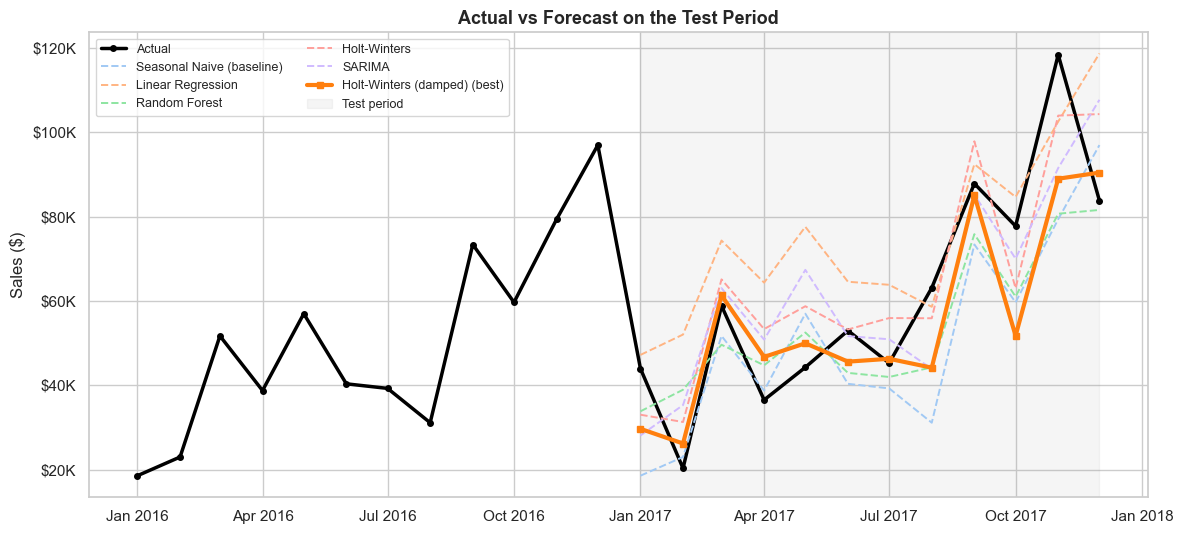

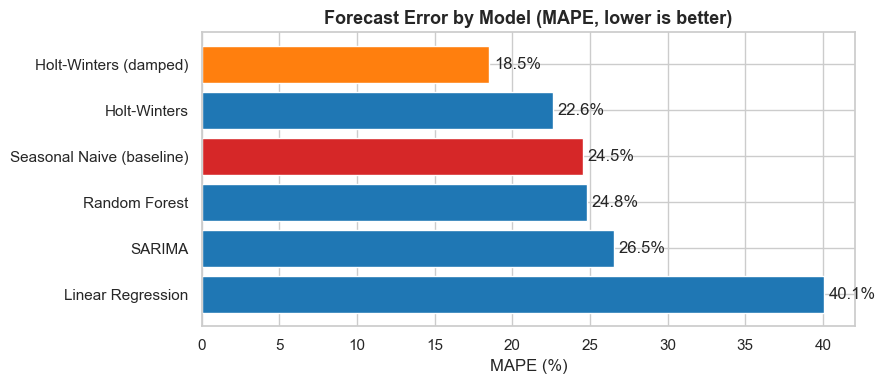

In [12]:
results.round(2).to_csv("outputs/model_comparison.csv")
print(f"Best model on the test period: {best_name}")
print(f"  MAPE {results.loc[best_name, 'MAPE %']:.1f}%  |  baseline MAPE {results.loc[BASELINE, 'MAPE %']:.1f}%")

# ---- Chart 1: actual vs predicted ----
fig, ax = plt.subplots(figsize=(12, 5.5))
hist_tail = series.iloc[-24:]
ax.plot(hist_tail.index, hist_tail.values, color="black", lw=2.5, marker="o", ms=4, label="Actual")
palette = dict(zip([n for n in MODELS if n != best_name], sns.color_palette("pastel", len(MODELS) - 1)))
for name, p in preds.items():
    if name == best_name:
        continue
    ax.plot(p.index, p.values, ls="--", lw=1.4, color=palette[name], label=name)
ax.plot(preds[best_name].index, preds[best_name].values, color=ORANGE, lw=3, marker="s", ms=5, label=f"{best_name} (best)")
ax.axvspan(test.index[0], test.index[-1], color="grey", alpha=0.08, label="Test period")
ax.set_title("Actual vs Forecast on the Test Period")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
ax.legend(loc="upper left", fontsize=9, ncol=2)
plt.tight_layout()
plt.savefig("images/05_actual_vs_predicted.png", dpi=150)
plt.show()

# ---- Chart 2: model comparison ----
fig, ax = plt.subplots(figsize=(9, 4))
order = results["MAPE %"].sort_values(ascending=False)
bar_colors = [ORANGE if n == best_name else RED if n == BASELINE else BLUE for n in order.index]
ax.barh(order.index, order.values, color=bar_colors)
for y, v in enumerate(order.values):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center")
ax.set_title("Forecast Error by Model (MAPE, lower is better)")
ax.set_xlabel("MAPE (%)")
plt.tight_layout()
plt.savefig("images/06_model_comparison.png", dpi=150)
plt.show()

### 8.2 Robustness check: rolling backtest
One 12-month test can be lucky or unlucky, especially with only 48 months of data. So every model is tested again on **three different periods**, each time trained only on the data before it. A model that wins consistently is more trustworthy than one that wins once.

In [13]:
folds = [(30, 6), (36, 6), (42, 6)]        # (months used for training, months to forecast)
bt = {}
for end, h in folds:
    tr, te = series.iloc[:end], series.iloc[end:end + h]
    label = f"{te.index[0]:%b %y}-{te.index[-1]:%b %y}"
    bt[label] = {name: metrics(te, run_model(name, tr, h))["MAPE %"] for name in MODELS}

backtest = pd.DataFrame(bt)
backtest["Average"] = backtest.mean(axis=1)
backtest = backtest.sort_values("Average")
backtest.round(1).to_csv("outputs/backtest_mape.csv")
print("MAPE (%) in each test period, trained only on earlier data:")
backtest.round(1)

MAPE (%) in each test period, trained only on earlier data:


,Jul 16-Dec 16,Jan 17-Jun 17,Jul 17-Dec 17,Average
Holt-Winters (damped),24.2,20.1,15.6,20.0
Seasonal Naive (baseline),22.0,23.6,25.4,23.7
Holt-Winters,29.1,28.2,17.1,24.8
Random Forest,26.0,31.8,18.1,25.3
SARIMA,25.6,35.2,17.7,26.1
Linear Regression,18.7,60.6,15.8,31.7


In [14]:
best_bt = backtest["Average"].idxmin()
print(f"Best on the 12-month test      : {best_name}")
print(f"Best on the rolling backtest   : {best_bt}")
print("-> The two checks AGREE, so the choice is robust." if best_name == best_bt
      else "-> The checks disagree. Mention this in the write-up and prefer the more consistent model.")

Best on the 12-month test      : Holt-Winters (damped)
Best on the rolling backtest   : Holt-Winters (damped)
-> The two checks AGREE, so the choice is robust.


### 8.3 Error analysis for the best model
Which months did it get wrong, and in which direction?

,Actual,Forecast,Error ($),Error (%)
Jan 2017,43971.0,29667.0,-14304.0,-33.0
Feb 2017,20301.0,26182.0,5880.0,29.0
Mar 2017,58872.0,61327.0,2455.0,4.0
Apr 2017,36522.0,46729.0,10207.0,28.0
May 2017,44261.0,49969.0,5708.0,13.0
Jun 2017,52982.0,45610.0,-7372.0,-14.0
Jul 2017,45264.0,46288.0,1024.0,2.0
Aug 2017,63121.0,44175.0,-18946.0,-30.0
Sep 2017,87867.0,85104.0,-2762.0,-3.0
Oct 2017,77777.0,51745.0,-26032.0,-33.0


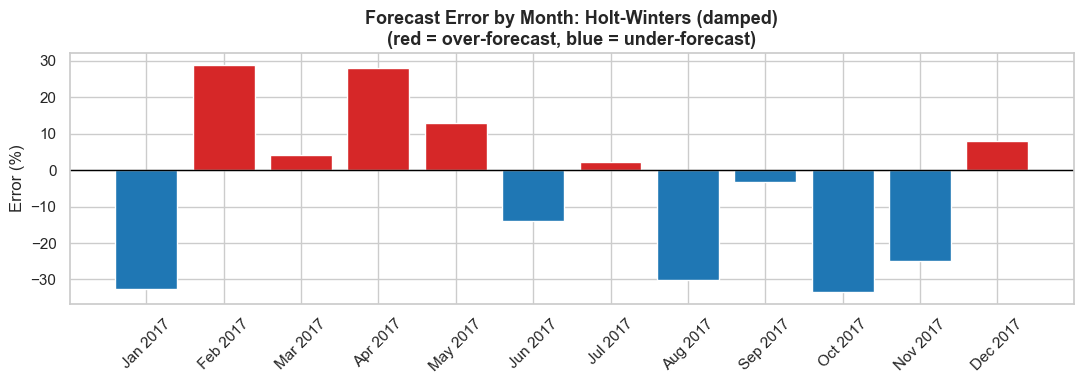

Largest misses: Oct 2017 (-33%), Jan 2017 (-33%), Aug 2017 (-30%)
Average bias: -5,577 $/month -> tends to UNDER-forecast


In [15]:
best_pred = preds[best_name]
err = pd.DataFrame({"Actual": test, "Forecast": best_pred})
err["Error ($)"] = err["Forecast"] - err["Actual"]
err["Error (%)"] = err["Error ($)"] / err["Actual"] * 100
err.index = err.index.strftime("%b %Y")
display(err.round(0))

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(err.index, err["Error (%)"], color=[RED if v > 0 else BLUE for v in err["Error (%)"]])
ax.axhline(0, color="black", lw=1)
ax.set_title(f"Forecast Error by Month: {best_name}\n(red = over-forecast, blue = under-forecast)")
ax.set_ylabel("Error (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("images/07_error_by_month.png", dpi=150)
plt.show()

worst = err["Error (%)"].abs().nlargest(3).index.tolist()
bias = err["Error ($)"].mean()
print("Largest misses:", ", ".join(f"{m} ({err.loc[m, 'Error (%)']:+.0f}%)" for m in worst))
print(f"Average bias: {bias:+,.0f} $/month ->",
      "tends to OVER-forecast" if bias > 0 else "tends to UNDER-forecast")

**How to explain the errors (write-up):**
- Sales in this dataset are lumpy: a handful of very large orders can make one month jump or collapse. No model can predict one-off big orders, so the biggest misses are in those spike or dip months.
- Compare the best model's error with the baseline. Beating the baseline, even modestly, shows the model adds real value over "same as last year".
- The **average bias** shows whether the model leans high or low, which matters for deciding how much safety stock to hold.

## 9. Forecast the next 12 months
The best model is **re-trained on all 48 months** (the more recent data it sees, the better) and used to forecast the 12 months after the data ends.

The shaded band is an **approximate 80% range** built from the model's test-period error (±1.28 × RMSE). It shows planners a realistic low and high case, not just one number.

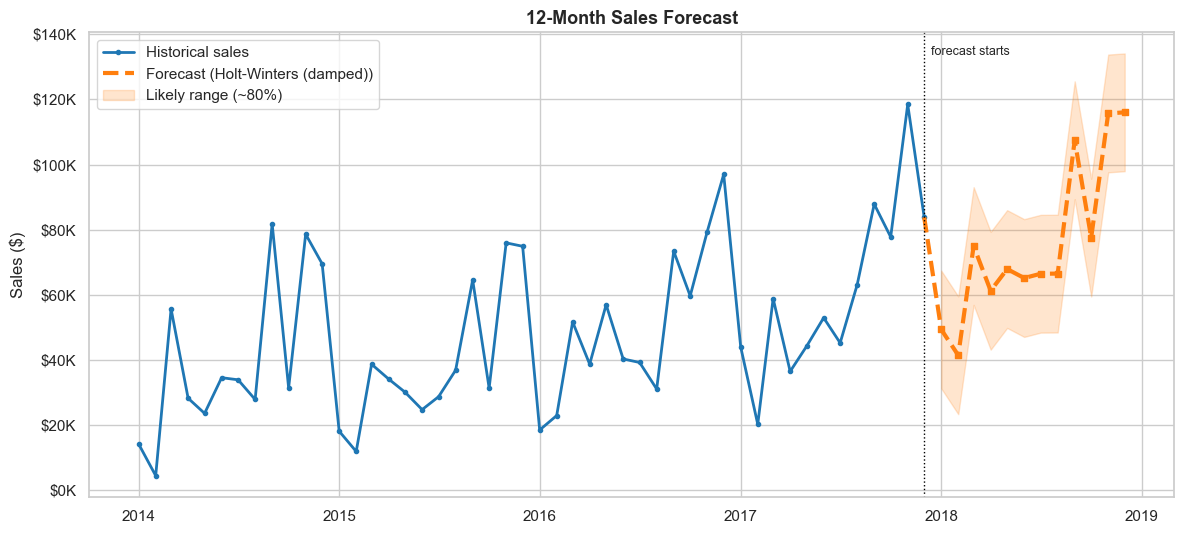

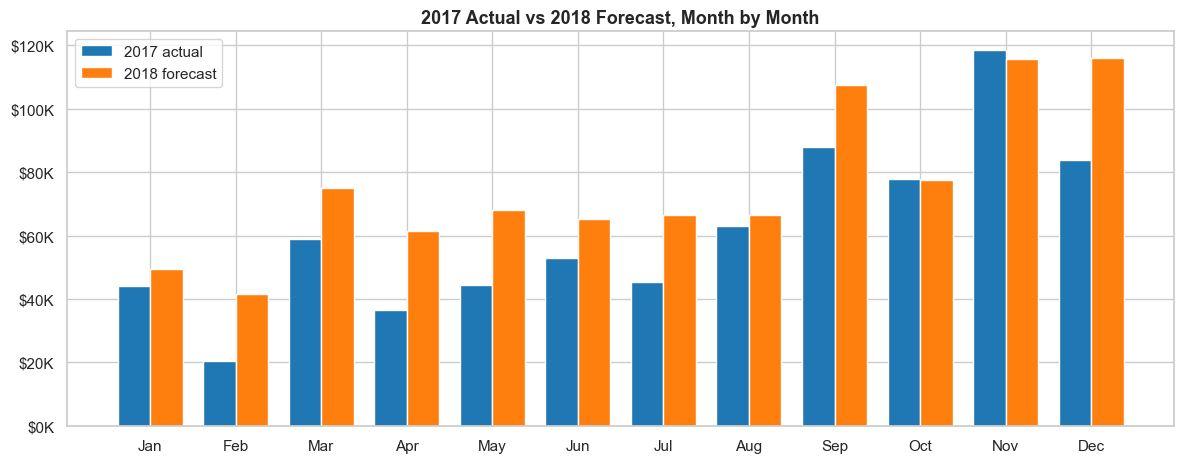

,Forecast,Low (80% range),High (80% range)
Month,,,
2018-01-01,49387.0,31316.0,67457.0
2018-02-01,41476.0,23405.0,59546.0
2018-03-01,74998.0,56927.0,93069.0
2018-04-01,61269.0,43199.0,79340.0
2018-05-01,67934.0,49863.0,86005.0
2018-06-01,65178.0,47108.0,83249.0
2018-07-01,66496.0,48425.0,84566.0
2018-08-01,66535.0,48464.0,84605.0
2018-09-01,107466.0,89396.0,125537.0


In [16]:
final_fc = run_model(best_name, series, 12)
band = 1.28 * results.loc[best_name, "RMSE"]
forecast_df = pd.DataFrame({
    "Forecast": final_fc,
    "Low (80% range)": (final_fc - band).clip(lower=0),
    "High (80% range)": final_fc + band,
}).round(0)
forecast_df.index.name = "Month"
forecast_df.to_csv("outputs/forecast_next_12_months.csv")

last_year = series.index[-1].year
next_year = final_fc.index[-1].year

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(series.index, series.values, color=BLUE, lw=2, marker="o", ms=3, label="Historical sales")
join = pd.concat([series.iloc[[-1]], final_fc])          # start the dashed line at the last real point
ax.plot(join.index, join.values, color=ORANGE, lw=3, ls="--", label=f"Forecast ({best_name})")
ax.scatter(final_fc.index, final_fc.values, color=ORANGE, marker="s", s=25, zorder=3)
ax.fill_between(final_fc.index, forecast_df["Low (80% range)"], forecast_df["High (80% range)"],
                color=ORANGE, alpha=0.2, label="Likely range (~80%)")
ax.axvline(series.index[-1], color="black", ls=":", lw=1)
ax.text(series.index[-1], ax.get_ylim()[1] * 0.97, "  forecast starts", va="top", fontsize=9)
ax.set_title("12-Month Sales Forecast")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Sales ($)")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("images/08_forecast.png", dpi=150)
plt.show()

# Same-month comparison: easy for non-technical readers
last_12 = series.iloc[-12:]
x = np.arange(12); w = 0.38
fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(x - w/2, last_12.values, w, color=BLUE, label=f"{last_year} actual")
ax.bar(x + w/2, final_fc.values, w, color=ORANGE, label=f"{next_year} forecast")
ax.set_xticks(x)
ax.set_xticklabels([calendar.month_abbr[m] for m in final_fc.index.month])
ax.set_title(f"{last_year} Actual vs {next_year} Forecast, Month by Month")
ax.yaxis.set_major_formatter(lambda x, _: f"${x/1000:,.0f}K")
ax.legend()
plt.tight_layout()
plt.savefig("images/09_year_over_year_forecast.png", dpi=150)
plt.show()

forecast_df

## 10. Business insights and recommendations
These statements are **generated from the results above**, so they always match the data.

In [17]:
top3 = seasonal_index.nlargest(3)
low2 = seasonal_index.nsmallest(2)
mname = lambda m: calendar.month_name[m]
peak_names = " / ".join(mname(m) for m in sorted(top3.index))     # calendar order
slow_names = " and ".join(mname(m) for m in sorted(low2.index))   # calendar order

q4_share = series[series.index.month.isin([11, 12])].groupby(series[series.index.month.isin([11, 12])].index.year).sum() \
           / yearly_total
q4_share = q4_share.mean() * 100

fc_total, ly_total = final_fc.sum(), last_12.sum()
fc_growth = (fc_total / ly_total - 1) * 100
peak_fc_month = final_fc.idxmax()
low_fc_month = final_fc.idxmin()
mape_best = results.loc[best_name, "MAPE %"]

insights = [
    f"SEASONALITY: Sales peak in {', '.join(mname(m) for m in sorted(top3.index))} "
    f"({', '.join(f'{mname(m)} {top3[m]:.1f}x' for m in sorted(top3.index))} an average month). "
    f"November and December alone bring about {q4_share:.0f}% of each year's sales.",
    f"SLOW MONTHS: {slow_names} are the weakest "
    f"({', '.join(f'{mname(m)} {low2[m]:.2f}x' for m in sorted(low2.index))} an average month).",
    f"GROWTH: Sales grew from ${yearly_total.iloc[0]/1000:,.0f}K in {yearly_total.index[0]} to "
    f"${yearly_total.iloc[-1]/1000:,.0f}K in {yearly_total.index[-1]}, about {cagr:.0f}% per year.",
    f"OUTLOOK: The model expects about ${fc_total/1000:,.0f}K of sales in the next 12 months "
    f"({fc_growth:+.0f}% vs the last 12 months). The strongest forecast month is {peak_fc_month:%B %Y} "
    f"(${final_fc.max()/1000:,.0f}K) and the weakest is {low_fc_month:%B %Y} (${final_fc.min()/1000:,.0f}K).",
    f"RELIABILITY: The model is typically off by about {mape_best:.1f}% per month "
    f"(baseline 'same as last year': {results.loc[BASELINE, 'MAPE %']:.1f}%). "
    f"Treat monthly numbers as planning guides and use the shaded range for safety buffers.",
]
recommendations = [
    f"INVENTORY: Build stock ahead of the peak. Order for {peak_names} 1 to 2 months early, "
    f"and avoid large purchases in {slow_names}.",
    f"STAFFING: Plan extra seasonal staff and shipping capacity for {peak_names}.",
    f"CASH FLOW: Expect cash to be tight in the slow months and strongest after the peak. Arrange credit or "
    f"delay big expenses accordingly.",
    f"RISK: Keep a safety buffer of roughly {mape_best:.0f}% on any monthly plan, and use the Low/High range when "
    f"deciding how much stock to commit to.",
    f"RE-FORECAST: Re-run this notebook every month with the newest sales so the forecast keeps improving.",
]

print("KEY INSIGHTS\n" + "-" * 60)
for i in insights: print("*", i, "\n")
print("RECOMMENDATIONS\n" + "-" * 60)
for r in recommendations: print("*", r, "\n")

KEY INSIGHTS
------------------------------------------------------------
* SEASONALITY: Sales peak in September, November, December (September 1.6x, November 1.8x, December 1.7x an average month). November and December alone bring about 30% of each year's sales. 

* SLOW MONTHS: January and February are the weakest (January 0.48x, February 0.30x an average month). 

* GROWTH: Sales grew from $484K in 2014 to $733K in 2017, about 15% per year. 

* OUTLOOK: The model expects about $910K of sales in the next 12 months (+24% vs the last 12 months). The strongest forecast month is December 2018 ($116K) and the weakest is February 2018 ($41K). 

* RELIABILITY: The model is typically off by about 18.5% per month (baseline 'same as last year': 24.5%). Treat monthly numbers as planning guides and use the shaded range for safety buffers. 

RECOMMENDATIONS
------------------------------------------------------------
* INVENTORY: Build stock ahead of the peak. Order for September / November / Dec

## 11. Limitations (be honest, reviewers value this)
- **Short history:** 48 months means only 4 yearly cycles. The model can't learn rare events, and error estimates are noisy. That's why a rolling backtest is included.
- **Lumpy sales:** a few very large orders swing monthly totals. Forecasting at the monthly level is smoother than weekly, but errors of 15 to 25% are normal for this dataset.
- **No outside information:** the model doesn't know about promotions, price changes, holidays, competitors or the economy. Adding these would likely improve accuracy.
- **Uncertainty range:** the shaded band is an approximation based on past errors, not a guarantee.
- **Future ideas:** forecast per Category or Region, add promotion/discount features, try Prophet, and tune hyperparameters with more data.

## 12. Auto-generate `README.md` and `requirements.txt` for GitHub

In [18]:
def md_table(frame, index_name="Model"):
    cols = [index_name] + list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for idx, row in frame.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [str(v) for v in row.values]) + " |")
    return "\n".join(lines)

res_md = results[["MAE", "RMSE", "MAPE %"]].round(1).copy()
res_md["MAE"] = res_md["MAE"].map(lambda v: f"${v:,.0f}")
res_md["RMSE"] = res_md["RMSE"].map(lambda v: f"${v:,.0f}")
res_md["MAPE %"] = res_md["MAPE %"].map(lambda v: f"{v:.1f}%")
res_md.index = [f"**{n}**" if n == best_name else n for n in res_md.index]

bt_md = backtest.round(1).astype(str) + "%"

readme = f"""# Sales & Demand Forecasting for Businesses

**Future Interns Machine Learning Internship, Task 1 (`FUTURE_ML_01`)**

## Problem statement
Retail businesses need to know how much they will sell in the coming months to plan inventory, cash flow and staffing, and to avoid overstocking or stock-outs. This project builds a model that forecasts the next 12 months of sales from historical data and presents the result in a business-friendly way.

## Dataset
Superstore Sales dataset, about 10,000 orders from January 2014 to December 2017.
Source: https://www.kaggle.com/datasets/vivek468/superstore-dataset-final
Orders were aggregated to **{len(series)} monthly totals**.

## Approach
1. **Cleaning:** removed duplicates, missing values and non-positive sales; parsed dates explicitly (month/day/year); inspected but kept large orders.
2. **Time series:** aggregated to monthly sales.
3. **Exploration:** seasonal decomposition, seasonal index by month and year-over-year growth.
4. **Feature engineering:** time index, month (also as sine/cosine) and last year's sales for the same month (`lag_12`). Only features known 12 months ahead were used to avoid data leakage.
5. **Models compared:** Seasonal Naive (baseline), Linear Regression, Random Forest, Holt-Winters, Holt-Winters (damped), SARIMA.
6. **Validation:** chronological split (train on {train.index[0]:%b %Y} to {train.index[-1]:%b %Y}, test on the last 12 months) plus a 3-period rolling backtest.

## Results (last 12 months held out)
{md_table(res_md)}

**Best model: {best_name}** with a MAPE of {results.loc[best_name, 'MAPE %']:.1f}% versus {results.loc[BASELINE, 'MAPE %']:.1f}% for the "same month last year" baseline.

Rolling backtest (MAPE in three different test periods):

{md_table(bt_md)}

## Key charts
![Monthly sales](images/01_monthly_sales.png)
![Decomposition](images/02_decomposition.png)
![Seasonality and growth](images/03_seasonality_and_growth.png)
![Actual vs predicted](images/05_actual_vs_predicted.png)
![Model comparison](images/06_model_comparison.png)
![Error by month](images/07_error_by_month.png)
![12-month forecast](images/08_forecast.png)
![Year over year](images/09_year_over_year_forecast.png)

## Business insights
{chr(10).join('- ' + i for i in insights)}

## Recommendations
{chr(10).join('- ' + r for r in recommendations)}

## Limitations
- Only 48 months of history, so error estimates are noisy.
- Sales are lumpy because of a few very large orders.
- The model has no information about promotions, prices or holidays.
- The forecast range is an approximation from past errors, not a guarantee.

## How to run
```bash
pip install -r requirements.txt
jupyter notebook notebook/sales_forecasting.ipynb
```
Place `Sample - Superstore.csv` (or the Kaggle zip) in the `data/` folder or next to the notebook.

## Repository structure
```
FUTURE_ML_01/
├── data/
├── notebook/sales_forecasting.ipynb
├── images/
├── outputs/      (model comparison and forecast CSVs)
├── README.md
└── requirements.txt
```
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

with open("requirements.txt", "w") as f:
    f.write("pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\nseaborn>=0.12\nscikit-learn>=1.3\nstatsmodels>=0.14\njupyter\n")

print("README.md and requirements.txt created")

README.md and requirements.txt created


## 13. Download everything (Colab)

In [19]:
import shutil
try:
    shutil.make_archive("FUTURE_ML_01_results", "zip", root_dir=".", base_dir="images")
    from google.colab import files
    for f in ["README.md", "requirements.txt", "FUTURE_ML_01_results.zip",
              "outputs/model_comparison.csv", "outputs/forecast_next_12_months.csv"]:
        files.download(f)
except ImportError:
    print("Not running in Colab. All files are saved in this folder: README.md, requirements.txt, images/, outputs/")

Not running in Colab. All files are saved in this folder: README.md, requirements.txt, images/, outputs/
